# 5 — Visualización orientada a preguntas

Un gráfico no es el objetivo: es evidencia para responder una pregunta. En cada ejercicio primero escribí qué querés averiguar, luego construí la agregación y finalmente redactá una conclusión de dos o tres oraciones.

Este notebook se ejecuta manualmente **después** de que el Job termina correctamente; no forma parte del pipeline.

In [0]:
dbutils.widgets.text("student_id", "alumno01", "01 - Identificador")
dbutils.widgets.dropdown("scale", "small", ["test", "small", "demo"], "02 - Escala")

In [0]:
%run ../common/config

In [0]:
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

catalog = spark.sql("SELECT current_catalog()").first()[0]
config = CourseConfig(catalog, dbutils.widgets.get("student_id"), dbutils.widgets.get("scale"))
daily = qualified_table(config, "gold_daily_sales")
risk = qualified_table(config, "gold_customer_risk")
batch = qualified_table(config, "gold_batch_summary")
for table in [daily, risk, batch]:
    assert spark.catalog.tableExists(table), f"Falta {table}. Ejecutá primero el Job completo."

## Ejemplo resuelto

**Pregunta:** ¿Qué categoría concentra el mayor monto vendido?

La agregación se hace con Spark. Sólo el resultado pequeño se convierte a Pandas para dibujarlo. Un gráfico de barras ordenado permite comparar categorías; un gráfico de torta haría más difícil comparar valores cercanos.

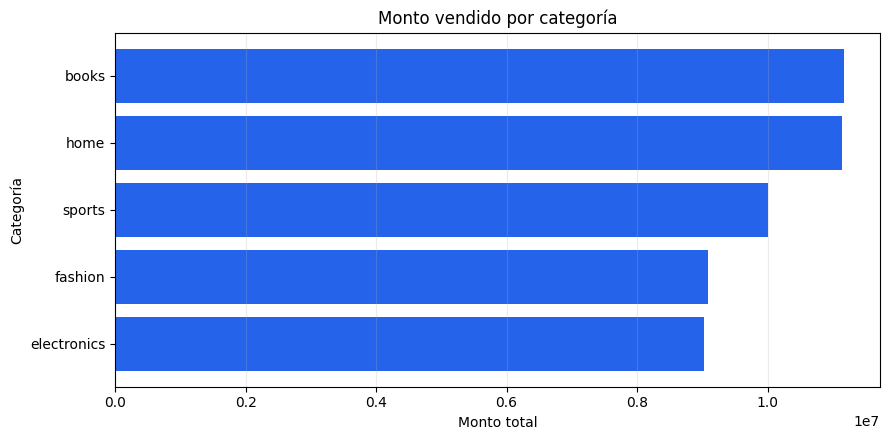

Respuesta: books es la categoría con mayor monto vendido (11,165,281.86).


In [0]:
category_sales = (spark.table(daily)
    .groupBy("category")
    .agg(F.sum("total_amount").alias("total_amount"))
    .orderBy(F.desc("total_amount")))

plot_data = category_sales.toPandas().sort_values("total_amount")
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(plot_data["category"], plot_data["total_amount"], color="#2563eb")
ax.set_title("Monto vendido por categoría")
ax.set_xlabel("Monto total")
ax.set_ylabel("Categoría")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

leader = category_sales.first()
print(f"Respuesta: {leader.category} es la categoría con mayor monto vendido ({leader.total_amount:,.2f}).")




## Consigna 1 — Evolución temporal

**Pregunta:** ¿Qué día tuvo el mayor monto vendido y ese día también fue el de mayor cantidad de transacciones?

Construí una visualización temporal que permita comparar ambas métricas sin ocultar sus unidades. Explicá si los dos máximos coinciden y qué implica que coincidan —o no— sobre el ticket promedio. Fuente sugerida: `gold_daily_sales`.

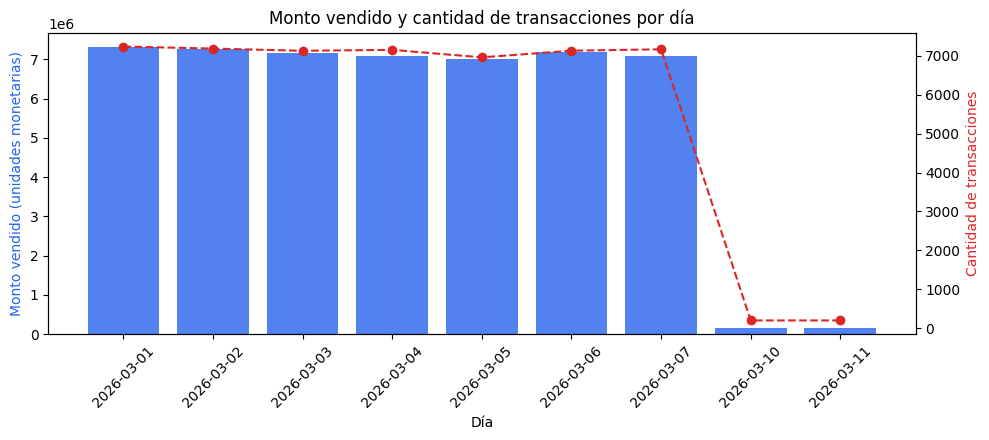

Mayor monto: 2026-03-01 (7,310,840.77)
Más transacciones: 2026-03-01 (7,236)
Coinciden: True
Ticket promedio del día de mayor monto: 1,010.34 | general: 1,001.63


In [0]:
by_day = (spark.table(daily)
    .groupBy("sale_date")
    .agg(F.sum("total_amount").alias("total_amount"),
         F.sum("transaction_count").alias("tx_count"))
    .withColumn("avg_ticket", F.col("total_amount") / F.col("tx_count"))
    .orderBy("sale_date"))

pdf = by_day.toPandas()
days = pdf["sale_date"].astype(str)

fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax1.bar(days, pdf["total_amount"], color="#2563eb", alpha=0.8, label="Monto vendido")
ax1.set_xlabel("Día")
ax1.set_ylabel("Monto vendido (unidades monetarias)", color="#2563eb")
ax1.tick_params(axis="x", rotation=45)

ax2 = ax1.twinx()
ax2.plot(days, pdf["tx_count"], color="#dc2626", marker="o", linestyle="--", label="Transacciones")
ax2.set_ylabel("Cantidad de transacciones", color="#dc2626")

ax1.set_title("Monto vendido y cantidad de transacciones por día")
fig.tight_layout()
plt.show()

top_amount = pdf.loc[pdf["total_amount"].idxmax()]
top_tx = pdf.loc[pdf["tx_count"].idxmax()]
overall_ticket = pdf["total_amount"].sum() / pdf["tx_count"].sum()
print(f"Mayor monto: {top_amount['sale_date']} ({top_amount['total_amount']:,.2f})")
print(f"Más transacciones: {top_tx['sale_date']} ({int(top_tx['tx_count']):,})")
print(f"Coinciden: {top_amount['sale_date'] == top_tx['sale_date']}")
print(f"Ticket promedio del día de mayor monto: {top_amount['avg_ticket']:,.2f} | general: {overall_ticket:,.2f}")

##Conclusión

Hay coincidencia entre el día de mayor monto vendido y el día con más transacciones. El ticket promedio del día de mayor monto vendido es mayor al ticket promedio general.
Puede deberse a que el mayor monto vendido se produzca en un día con mayor actividad.

## Consigna 2 — Canal y fraude

**Pregunta:** ¿Qué canal de pago presenta la mayor tasa de fraude? ¿La conclusión se sostiene al considerar el número de transacciones de cada canal?

Mostrá tasa y volumen de manera legible. No compares sólo cantidades de fraude: calculá el denominador correcto. Fuente sugerida: `gold_daily_sales`.

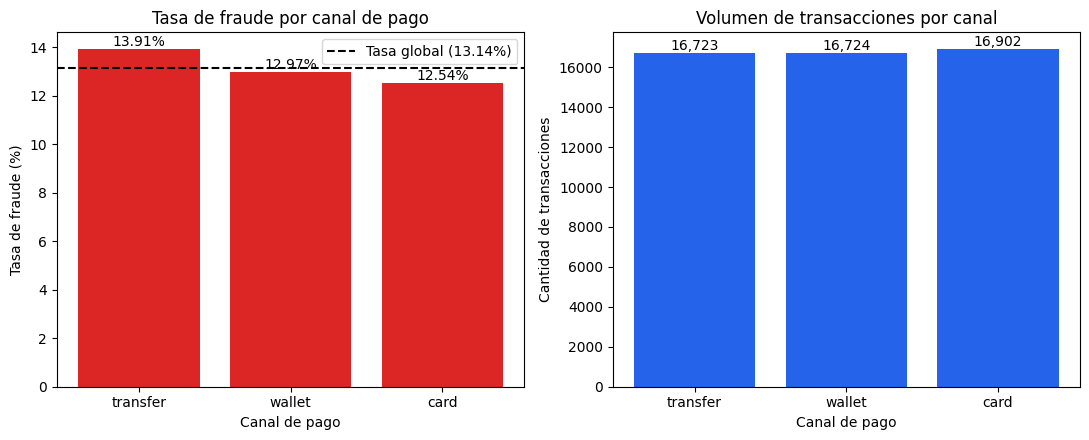

payment_channel,fraud_tx,tx_count,fraud_rate
transfer,2327,16723,0.1391496741015368
wallet,2169,16724,0.1296938531451806
card,2119,16902,0.12536977872441132


In [0]:
CHANNEL_COL = "payment_channel"  # ajustar si la columna se llama distinto

by_channel = (spark.table(daily)
    .groupBy(CHANNEL_COL)
    .agg(F.sum("fraud_transactions").alias("fraud_tx"),
         F.sum("transaction_count").alias("tx_count"))
    .withColumn("fraud_rate", F.col("fraud_tx") / F.col("tx_count"))
    .orderBy(F.desc("fraud_rate")))

pdf = by_channel.toPandas().sort_values("fraud_rate", ascending=False)
global_rate = pdf["fraud_tx"].sum() / pdf["tx_count"].sum()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))

ax1.bar(pdf[CHANNEL_COL], pdf["fraud_rate"] * 100, color="#dc2626")
ax1.axhline(global_rate * 100, color="black", linestyle="--", label=f"Tasa global ({global_rate*100:.2f}%)")
ax1.set_title("Tasa de fraude por canal de pago")
ax1.set_xlabel("Canal de pago")
ax1.set_ylabel("Tasa de fraude (%)")
ax1.legend()
for i, v in enumerate(pdf["fraud_rate"] * 100):
    ax1.text(i, v, f"{v:.2f}%", ha="center", va="bottom")

ax2.bar(pdf[CHANNEL_COL], pdf["tx_count"], color="#2563eb")
ax2.set_title("Volumen de transacciones por canal")
ax2.set_xlabel("Canal de pago")
ax2.set_ylabel("Cantidad de transacciones")
for i, v in enumerate(pdf["tx_count"]):
    ax2.text(i, v, f"{int(v):,}", ha="center", va="bottom")

fig.tight_layout()
plt.show()

display(pdf)

##Conclusión

Se observa que el canal de pago con mayor tasa de fraude es transfer, seguida de wallet y card.
El canal de pago con mayor volumen de transacciones es card, sin embargo, es el que menos fraude genera, por lo que no se corresponde el nivel de transacciones con el nivel de fraude.

## Consigna 3 — Concentración geográfica y de producto

**Pregunta:** ¿Qué combinación de país y categoría genera el mayor monto? ¿Existe una categoría dominante en todos los países o cambia según el mercado?

Elegí una visualización que permita comparar simultáneamente países y categorías. Justificá brevemente por qué ese tipo de gráfico es adecuado. Fuente sugerida: `gold_daily_sales`.

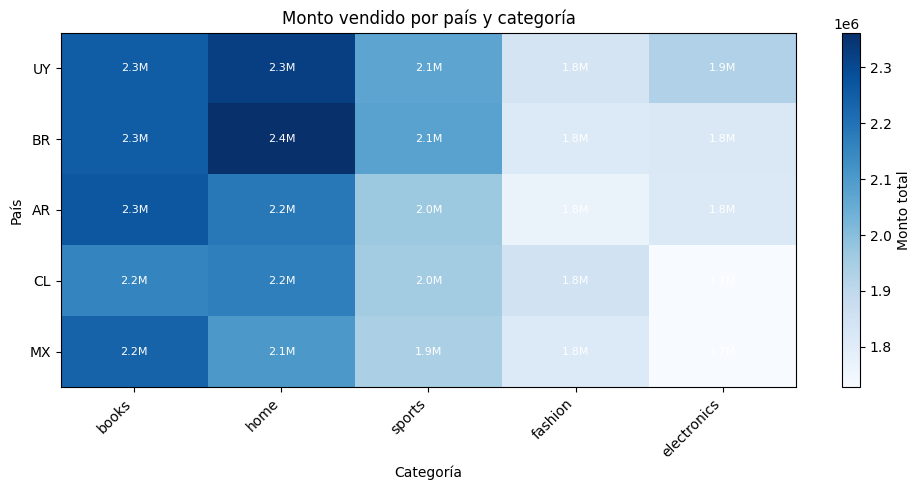

Máximo global: BR - home (2,361,959.97)
Categoría líder por país:
country
UY     home
BR     home
AR    books
CL     home
MX    books


In [0]:
COUNTRY_COL = "country"  # ajustar si se llama distinto

by_cc = (spark.table(daily)
    .groupBy(COUNTRY_COL, "category")
    .agg(F.sum("total_amount").alias("total_amount")))

pdf = by_cc.toPandas()
pdf["total_amount"] = pdf["total_amount"].astype(float)

pivot = pdf.pivot(index=COUNTRY_COL, columns="category", values="total_amount").fillna(0)
pivot = pivot.loc[pivot.sum(axis=1).sort_values(ascending=False).index,
                  pivot.sum(axis=0).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(10, 5))
im = ax.imshow(pivot.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels(pivot.columns, rotation=45, ha="right")
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index)
ax.set_xlabel("Categoría")
ax.set_ylabel("País")
ax.set_title("Monto vendido por país y categoría")
fig.colorbar(im, ax=ax, label="Monto total")

vmax = pivot.values.max()
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v = pivot.values[i, j]
        ax.text(j, i, f"{v/1e6:.1f}M", ha="center", va="center",
                color="white" if v > vmax * 0.6 else "black", fontsize=8)

fig.tight_layout()
plt.show()

top = pdf.loc[pdf["total_amount"].idxmax()]
print(f"Máximo global: {top[COUNTRY_COL]} - {top['category']} ({top['total_amount']:,.2f})")
print("Categoría líder por país:")
print(pivot.idxmax(axis=1).to_string())



##Conclusión

La combinación de país y categoría que genera mayor monto es Brasil en la categoría Home.
Se observa que "Home" es la categoría dominante entre países, seguida de "Books" y "Sports".

## Consigna 4 — Calidad del pipeline

**Pregunta:** ¿Qué proporción de cada lote fue aceptada y rechazada? ¿El lote nuevo presenta una calidad diferente del lote inicial?

Compará lotes usando proporciones además de cantidades absolutas. Señalá cualquier limitación de comparar lotes de tamaños distintos. Fuente sugerida: `gold_batch_summary`.

source_batch_id,accepted_transactions,rejected_transactions,total_amount,fraud_transactions,refreshed_at
batch_002,200,2,144813.00,27,2026-10-03T13:27:01.255Z
initial,49948,51,50139370.34,6560,2026-10-03T13:27:01.255Z
batch_003,201,2,147014.99,28,2026-10-03T13:27:01.255Z


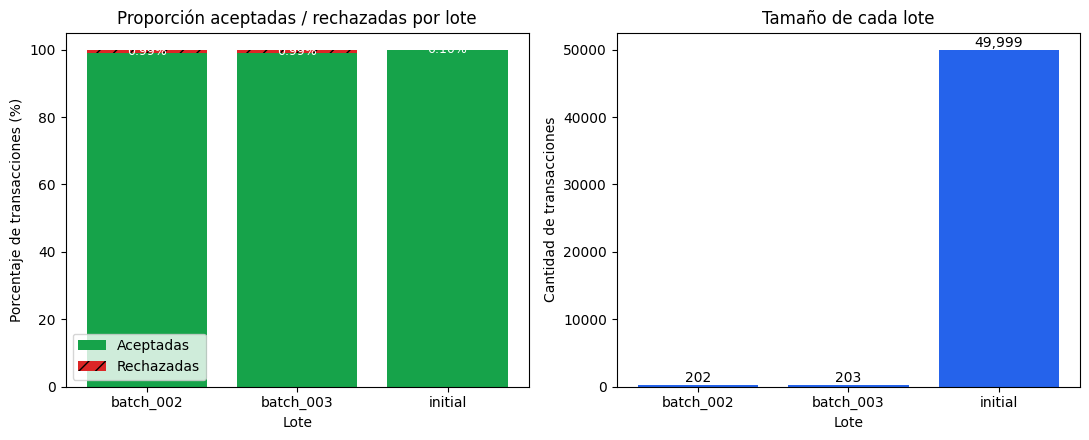

source_batch_id  accepted  rejected   total  rejected_pct
      batch_002     200.0       2.0   202.0      0.990099
      batch_003     201.0       2.0   203.0      0.985222
        initial   49948.0      51.0 49999.0      0.102002


In [0]:
BATCH_COL = "source_batch_id"

summary = spark.table(batch)
display(summary)  # para ver las columnas reales

pdf = summary.toPandas()
pdf["accepted"] = pdf["accepted_transactions"].astype(float)
pdf["rejected"] = pdf["rejected_transactions"].astype(float)
pdf["total"] = pdf["accepted"] + pdf["rejected"]
pdf["accepted_pct"] = pdf["accepted"] / pdf["total"] * 100
pdf["rejected_pct"] = pdf["rejected"] / pdf["total"] * 100
pdf = pdf.sort_values(BATCH_COL)
labels = pdf[BATCH_COL].astype(str)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))

ax1.bar(labels, pdf["accepted_pct"], color="#16a34a", label="Aceptadas")
ax1.bar(labels, pdf["rejected_pct"], bottom=pdf["accepted_pct"], color="#dc2626", hatch="//", label="Rechazadas")
ax1.set_title("Proporción aceptadas / rechazadas por lote")
ax1.set_xlabel("Lote")
ax1.set_ylabel("Porcentaje de transacciones (%)")
ax1.legend()
for i, v in enumerate(pdf["rejected_pct"]):
    ax1.text(i, 100 - v / 2, f"{v:.2f}%", ha="center", va="center", color="white", fontsize=9)

ax2.bar(labels, pdf["total"], color="#2563eb")
ax2.set_title("Tamaño de cada lote")
ax2.set_xlabel("Lote")
ax2.set_ylabel("Cantidad de transacciones")
for i, v in enumerate(pdf["total"]):
    ax2.text(i, v, f"{int(v):,}", ha="center", va="bottom")

fig.tight_layout()
plt.show()

print(pdf[[BATCH_COL, "accepted", "rejected", "total", "rejected_pct"]].to_string(index=False))

##Conclusión

Hay un porcentaje muy bajo de transacciones rechazadas, que oscila entre 0.01% y 0.03%.
La calidad de transacciones del lote inicial es mayor que el resto, batch_002 y 003 cuentan con un 99.99% de aceptadas.

## Criterios de entrega

Para cada consigna entregá: (1) la transformación de datos, (2) un gráfico, y (3) una conclusión de dos o tres oraciones que responda explícitamente la pregunta.

Cada gráfico debe tener título informativo, ejes y unidades legibles, categorías ordenadas cuando corresponda y una elección de color que no sea la única forma de comunicar el significado. No conviertas una tabla Silver completa a Pandas: agregá primero con Spark y convertí sólo el resultado pequeño.